In [216]:
import pandas as pd
import numpy as np

dt = pd.read_csv('https://drive.google.com/uc?export=download&id=1OMX2KdA6KeZgkW2GOv33bHdZmH7Ve_JI')



In [217]:
print(dt.head())
print(dt.tail())


  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

In [218]:
print(dt.info())#tất cả dữ liệu đều là string

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

In [219]:
print(dt.shape)
print(dt.nunique())
#chuyển về boolean class, bruises, gill-attachment, gill-spacing, gill-size, stalk-shape
#Liệu có nên bỏ veil-type hay ko vì chỉ có 1 đặt điểm?


(8124, 23)
class                        2
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   5
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64


In [220]:
print(dt.describe())

       class cap-shape cap-surface cap-color bruises  odor gill-attachment  \
count   8124      8124        8124      8124    8124  8124            8124   
unique     2         6           4        10       2     9               2   
top        e         x           y         n       f     n               f   
freq    4208      3656        3244      2284    4748  3528            7914   

       gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
count          8124      8124       8124  ...                     8124   
unique            2         2         12  ...                        4   
top               c         b          b  ...                        s   
freq           6812      5612       1728  ...                     4936   

       stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
count                    8124                   8124      8124       8124   
unique                      9                      9         1          4   
top    

In [221]:
for col in dt.columns:
    print(f"\n================")
    print(dt[col].value_counts(dropna=False))
# có các giá trị là ? ở cột stalk-root


class
e    4208
p    3916
Name: count, dtype: int64

cap-shape
x    3656
f    3152
k     828
b     452
s      32
c       4
Name: count, dtype: int64

cap-surface
y    3244
s    2556
f    2320
g       4
Name: count, dtype: int64

cap-color
n    2284
g    1840
e    1500
y    1072
w    1040
b     168
p     144
c      44
u      16
r      16
Name: count, dtype: int64

bruises
f    4748
t    3376
Name: count, dtype: int64

odor
n    3528
f    2160
y     576
s     576
a     400
l     400
p     256
c     192
m      36
Name: count, dtype: int64

gill-attachment
f    7914
a     210
Name: count, dtype: int64

gill-spacing
c    6812
w    1312
Name: count, dtype: int64

gill-size
b    5612
n    2512
Name: count, dtype: int64

gill-color
b    1728
p    1492
w    1202
n    1048
g     752
h     732
u     492
k     408
e      96
y      86
o      64
r      24
Name: count, dtype: int64

stalk-shape
t    4608
e    3516
Name: count, dtype: int64

stalk-root
b    3776
?    2480
e    1120
c     556
r     19

In [222]:
#tính xác xuất của các giá trị xuất hiện trong 1 cột
for col in dt.columns:
    print(dt[col].value_counts(dropna=False)/dt[col].shape[0])


class
e    0.517971
p    0.482029
Name: count, dtype: float64
cap-shape
x    0.450025
f    0.387986
k    0.101920
b    0.055638
s    0.003939
c    0.000492
Name: count, dtype: float64
cap-surface
y    0.399311
s    0.314623
f    0.285574
g    0.000492
Name: count, dtype: float64
cap-color
n    0.281142
g    0.226489
e    0.184638
y    0.131955
w    0.128016
b    0.020679
p    0.017725
c    0.005416
u    0.001969
r    0.001969
Name: count, dtype: float64
bruises
f    0.584441
t    0.415559
Name: count, dtype: float64
odor
n    0.434269
f    0.265879
y    0.070901
s    0.070901
a    0.049237
l    0.049237
p    0.031512
c    0.023634
m    0.004431
Name: count, dtype: float64
gill-attachment
f    0.974151
a    0.025849
Name: count, dtype: float64
gill-spacing
c    0.838503
w    0.161497
Name: count, dtype: float64
gill-size
b    0.690793
n    0.309207
Name: count, dtype: float64
gill-color
b    0.212703
p    0.183653
w    0.147957
n    0.129000
g    0.092565
h    0.090103
u    0.060561
k  

In [223]:
print(dt.isnull().sum())
# không có null cả dữ liệu

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


## Cleaning

In [224]:
print(dt.shape)
dt = dt.drop_duplicates()
print(dt.shape)

#Kiểm tra các mẫu có cùng features nhưng khác label
features = dt.drop(columns=['class'])
features = features.drop_duplicates()
print(features.shape)

#Kết luận ko có giá trị trùng

(8124, 23)
(8124, 23)
(8124, 22)


#### thử nghiệm 2 trường hợp: cho giá trị ? là nan, hoặc cho ? là 1 điểm đặc trưng là unknow

In [225]:
# cho giá trị ? là nan
dt = dt.replace('?',np.nan)#? đổi về unknown để chuyển về nan test

# Kiểm tra missing values
missing = pd.DataFrame({
    'Missing Count': dt.isnull().sum(),
    'Missing Rate (%)': dt.isnull().mean() * 100
})

print(missing[missing['Missing Count'] > 0])

            Missing Count  Missing Rate (%)
stalk-root           2480         30.526834


In [226]:
# cho giá trị ? là unknow
dt['stalk-root'] = dt['stalk-root'].fillna('unknown')

print(dt.isnull().sum().sum())

0


In [227]:
#chuẩn hóa về chữ thường cho từng cột
for col in dt.columns:
    dt[col] = dt[col].str.lower().str.strip()


In [228]:
#bỏ cột veil-type vì chỉ có 1 giá trị, ko có giá trị trong phân loại
dt = dt.drop(columns=['veil-type'])


In [229]:
# kiểm tra xem có giá trị nào không đúng với quy ước của csv hay ko, để xóa nếu cần thiết
valid_values = {
    'class': ['e', 'p'],
    'cap-shape': ['b', 'c', 'x', 'f', 'k', 's'],
    'cap-surface': ['f', 'g', 'y', 's'],
    'cap-color': ['n', 'b', 'c', 'g', 'r', 'p', 'u', 'e', 'w', 'y'],
    'bruises': ['t', 'f'],
    'odor': ['a', 'l', 'c', 'y', 'f', 'm', 'n', 'p', 's'],
    'gill-attachment': ['a', 'd', 'f', 'n'],
    'gill-spacing': ['c', 'w', 'd'],
    'gill-size': ['b', 'n'],
    'gill-color': ['k', 'n', 'b', 'h', 'g', 'r', 'o', 'p', 'u', 'e', 'w', 'y'],
    'stalk-shape': ['e', 't'],
    'stalk-root': ['b', 'c', 'u', 'e', 'z', 'r', '?'],
    'stalk-surface-above-ring': ['f', 'y', 'k', 's'],
    'stalk-surface-below-ring': ['f', 'y', 'k', 's'],
    'stalk-color-above-ring': ['n', 'b', 'c', 'g', 'o', 'p', 'e', 'w', 'y'],
    'stalk-color-below-ring': ['n', 'b', 'c', 'g', 'o', 'p', 'e', 'w', 'y'],
    'veil-type': ['p', 'u'],
    'veil-color': ['n', 'o', 'w', 'y'],
    'ring-number': ['n', 'o', 't'],
    'ring-type': ['c', 'e', 'f', 'l', 'n', 'p', 's', 'z'],
    'spore-print-color': ['k', 'n', 'b', 'h', 'r', 'o', 'u', 'w', 'y'],
    'population': ['a', 'c', 'n', 's', 'v', 'y'],
    'habitat': ['g', 'l', 'm', 'p', 'u', 'w', 'd']
}


results = []
invalid_rows = {}

for col, valid in valid_values.items():

    if col not in dt.columns:
        print(f"Không tìm thấy cột: {col}")
        continue

    # Kiểm tra giá trị không hợp lệ
    mask = ~dt[col].isin(valid)

    # Đếm số giá trị sai
    count = mask.sum()

    # Lưu thông tin
    results.append({
        'Column': col,
        'Invalid_Count': count
    })

    # Lưu các dòng chứa giá trị sai
    if count > 0:
        invalid_rows[col] = dt[mask]

# Bảng thống kê
result_dt = pd.DataFrame(results)

print("=== SỐ LƯỢNG GIÁ TRỊ SAI THEO TỪNG CỘT ===")
print(result_dt.to_string(index=False))

print("\nTổng số giá trị sai:",
        result_dt['Invalid_Count'].sum())

print("\n=== CÁC GIÁ TRỊ KHÔNG HỢP LỆ ===")

for col, data in invalid_rows.items():
    print(f"\nCột: {col}")
    print(data[[col]].value_counts())

#kết luận dữ liệu đă ổn và có thể train


Không tìm thấy cột: veil-type
=== SỐ LƯỢNG GIÁ TRỊ SAI THEO TỪNG CỘT ===
                  Column  Invalid_Count
                   class              0
               cap-shape              0
             cap-surface              0
               cap-color              0
                 bruises              0
                    odor              0
         gill-attachment              0
            gill-spacing              0
               gill-size              0
              gill-color              0
             stalk-shape              0
              stalk-root           2480
stalk-surface-above-ring              0
stalk-surface-below-ring              0
  stalk-color-above-ring              0
  stalk-color-below-ring              0
              veil-color              0
             ring-number              0
               ring-type              0
       spore-print-color              0
              population              0
                 habitat              0

Tổng s

## tranformation

In [ ]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

x = dt.drop(columns=["class"])
y = dt["class"].map({"e": 0, "p": 1})

# Binary categorical columns
binary_cols = [
    "bruises",
    "gill-attachment",
    "gill-spacing",
    "gill-size",
    "stalk-shape"
]

# Multi-category columns
onehot_cols = [
    "cap-shape",
    "cap-surface",
    "cap-color",
    "odor",
    "gill-color",
    "stalk-root",
    "stalk-surface-above-ring",
    "stalk-surface-below-ring",
    "stalk-color-above-ring",
    "stalk-color-below-ring",
    "veil-color",
    "ring-number",
    "ring-type",
    "spore-print-color",
    "population",
    "habitat"
]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.3,
    random_state=42,
    # stratify=y#test xem nếu ko đều thì có sự khác biệt ko


)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "binary",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            binary_cols
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore"),
            onehot_cols
        )
    ]
)

# Fit on training data only
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Original features:", X_train.shape[1])
print("Encoded features:", X_train_encoded.shape[1])


Original features: 21
Encoded features: 111


## train

In [246]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,# số lượng cây
    max_depth=None,# không giới hạn độ sâu của cây
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=27,#Cố định tính ngẫu nhiên để mỗi lần bạn chạy lại code đều cho ra cùng một kết quả
    n_jobs=-1, #Huy động toàn bộ số nhân (core) của CPU trên máy tính để chạy song song cho nhanh.
    class_weight="balanced"# phải thử nghiệm xem để hay ko để sẽ ra giá trị tốt hơn, kết quả là có, độ chính xác có cải thiện nhưng tùy trường hợp
)

# Train model
rf_model.fit(X_train_encoded, y_train)

# Predict
y_pred = rf_model.predict(X_test_encoded)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Edible", "Poisonous"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00      1257
   Poisonous       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438


Confusion Matrix:
[[1257    0]
 [   0 1181]]


## trực quan hóa các đặt trưng quan trọng

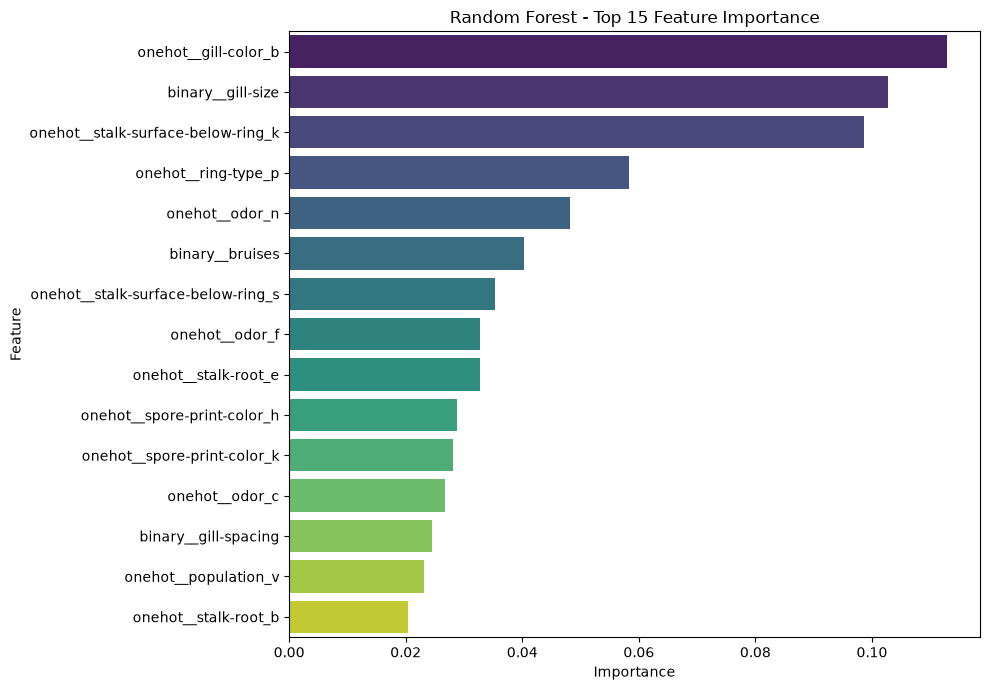

In [238]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest - Top 15 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [247]:
# Dự đoán dữ liệu nấm mới
# Các mã giá trị phải dùng cùng quy ước với bộ dữ liệu mushroom gốc
new_mushrooms = pd.DataFrame([
    {
        "cap-shape": "x", "cap-surface": "s", "cap-color": "n",
        "bruises": "t", "odor": "a", "gill-attachment": "f",
        "gill-spacing": "c", "gill-size": "b", "gill-color": "k",
        "stalk-shape": "e", "stalk-root": "b",
        "stalk-surface-above-ring": "s", "stalk-surface-below-ring": "s",
        "stalk-color-above-ring": "w", "stalk-color-below-ring": "w",
        "veil-color": "w", "ring-number": "o", "ring-type": "p",
        "spore-print-color": "k", "population": "s", "habitat": "u"
    },
    {
        "cap-shape": "k", "cap-surface": "y", "cap-color": "n",
        "bruises": "f", "odor": "y", "gill-attachment": "f",
        "gill-spacing": "c", "gill-size": "n", "gill-color": "b",
        "stalk-shape": "t", "stalk-root": "unknown",
        "stalk-surface-above-ring": "k", "stalk-surface-below-ring": "k",
        "stalk-color-above-ring": "w", "stalk-color-below-ring": "w",
        "veil-color": "w", "ring-number": "o", "ring-type": "e",
        "spore-print-color": "w", "population": "v", "habitat": "l"
    }
])

# Giữ đúng thứ tự cột đã dùng khi train
new_mushrooms = new_mushrooms[x.columns]

valid_values = {
    "cap-shape": ["b", "c", "x", "f", "k", "s"],
    "cap-surface": ["f", "g", "y", "s"],
    "cap-color": ["n", "b", "c", "g", "r", "p", "u", "e", "w", "y"],
    "bruises": ["t", "f"],
    "odor": ["a", "l", "c", "y", "f", "m", "n", "p", "s"],
    "gill-attachment": ["a", "d", "f", "n"],
    "gill-spacing": ["c", "w", "d"],
    "gill-size": ["b", "n"],
    "gill-color": ["k", "n", "b", "h", "g", "r", "o", "p", "u", "e", "w", "y"],
    "stalk-shape": ["e", "t"],
    "stalk-root": ["b", "c", "u", "e", "z", "r", "unknown"],
    "stalk-surface-above-ring": ["f", "y", "k", "s"],
    "stalk-surface-below-ring": ["f", "y", "k", "s"],
    "stalk-color-above-ring": ["n", "b", "c", "g", "o", "p", "e", "w", "y"],
    "stalk-color-below-ring": ["n", "b", "c", "g", "o", "p", "e", "w", "y"],
    "veil-color": ["n", "o", "w", "y"],
    "ring-number": ["n", "o", "t"],
    "ring-type": ["c", "e", "f", "l", "n", "p", "s", "z"],
    "spore-print-color": ["k", "n", "b", "h", "r", "o", "u", "w", "y"],
    "population": ["a", "c", "n", "s", "v", "y"],
    "habitat": ["g", "l", "m", "p", "u", "w", "d"]
}

invalid = {
    col: sorted(set(new_mushrooms[col]) - set(values))
    for col, values in valid_values.items()
    if set(new_mushrooms[col]) - set(values)
}
if invalid:
    raise ValueError(f"Dữ liệu mới chứa giá trị không hợp lệ: {invalid}")

new_encoded = preprocessor.transform(new_mushrooms)
predictions = rf_model.predict(new_encoded)
probabilities = rf_model.predict_proba(new_encoded)

result = new_mushrooms.copy()
result["Prediction"] = ["Edible" if label == 0 else "Poisonous" for label in predictions]
result["Edible_probability"] = probabilities[:, 0]
result["Poisonous_probability"] = probabilities[:, 1]

print(result[["Prediction", "Edible_probability", "Poisonous_probability"]])


  Prediction  Edible_probability  Poisonous_probability
0     Edible                0.65                   0.35
1  Poisonous                0.00                   1.00
